# Bài toán 2 — Gợi ý kỹ năng tiếp theo từ role và kỹ năng đã biết

Với role mục tiêu và những kỹ năng người học đã có, gợi ý một kỹ năng phù hợp để học tiếp. Khai phá luật theo từng role, tương đương `{ROLE, known skill(s)} → next skill`, rồi so sánh Apriori và FP-Growth với baseline tần suất theo role.

## 1. Định nghĩa bài toán và tránh rò rỉ dữ liệu

Đây là bài toán **khôi phục kỹ năng bị ẩn**, không phải dự đoán thứ tự học theo thời gian. Với mỗi tin tuyển dụng ở tập test, ẩn có kiểm soát 20% kỹ năng đã trích xuất; các kỹ năng còn lại cùng role tạo thành ngữ cảnh truy vấn, còn kỹ năng bị ẩn là mục tiêu. Luật chỉ được học từ các fold train. Baseline nhận cùng role và loại các kỹ năng đã biết khỏi danh sách gợi ý, nhưng không dùng ngữ cảnh skill. Loại `Other` và tin không có skill khỏi dữ liệu; tin chỉ có một skill vẫn được dùng trong train nhưng không dùng làm truy vấn test vì không thể vừa có ngữ cảnh vừa có mục tiêu.

In [1]:
import ast, json, math, time, tracemalloc
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from sklearn.model_selection import StratifiedKFold

DATA_DIR = Path("../data/processed")
RESULT_DIR = Path("../result/problem_2")
FIGURES_DIR = RESULT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE, N_SPLITS = 42, 5
MIN_SUPPORT_COUNT, MIN_CONFIDENCE, MIN_LIFT = 5, 0.20, 1.20
MAX_ITEMSET_LENGTH = 3  # per role: up to two known skills -> one recommended skill
TOP_K_VALUES, MASK_RATIO = [5, 10], 0.20

def parse_skill_list(value):
    if isinstance(value, list): parsed = value
    elif isinstance(value, str):
        try: parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError): parsed = []
    else: parsed = []
    if not isinstance(parsed, list): return []
    return list(dict.fromkeys(x.strip() for x in parsed if isinstance(x, str) and x.strip()))

jobs_all = pd.read_csv(DATA_DIR / "processed_jobs.csv")
jobs_all["skills_final"] = jobs_all["skills_final"].apply(parse_skill_list)
role_mask = jobs_all["role_group"].fillna("Other").ne("Other")
jobs = jobs_all.loc[role_mask].reset_index(drop=True)
transactions = pd.read_csv(DATA_DIR / "transaction_matrix.csv").replace(
    {"True": True, "False": False}
).fillna(False).astype(bool).reset_index(drop=True)
if len(jobs) != len(transactions):
    raise ValueError("processed_jobs và transaction_matrix không khớp thứ tự dòng sau khi bỏ Other")
role_cols = [c for c in transactions if c.startswith("ROLE_")]
skill_cols = [c for c in transactions if not c.startswith("ROLE_")]
role_from_matrix = transactions[role_cols].idxmax(axis=1).str.replace("ROLE_", "", n=1, regex=False)
if not role_from_matrix.equals(jobs.role_group.reset_index(drop=True)):
    raise ValueError("Nhãn role không khớp thứ tự dòng của ma trận giao dịch")
has_skills = jobs.skills_final.map(bool)
excluded_empty = int((~has_skills).sum())
jobs = jobs.loc[has_skills].reset_index(drop=True)
transactions = transactions.loc[has_skills].reset_index(drop=True)
query_mask = jobs.skills_final.map(lambda xs: len(set(xs) & set(skill_cols)) >= 2)
excluded_short = int((~query_mask).sum())
jobs["query_eligible"] = query_mask.to_numpy()
if jobs.role_group.value_counts().min() < N_SPLITS:
    raise ValueError("Một role có quá ít tin để chia phân tầng 5-fold")
print(f"Tin train có skill: {len(jobs)}; truy vấn test đủ điều kiện: {int(query_mask.sum())}; "
      f"loại do thiếu skill: {excluded_empty}; tin không đủ làm truy vấn: {excluded_short}; "
      f"số role: {jobs.role_group.nunique()}")
display(jobs.loc[jobs.query_eligible, "role_group"].value_counts().rename("Số truy vấn hợp lệ").to_frame())

Tin train có skill: 1501; truy vấn test đủ điều kiện: 1289; loại do thiếu skill: 329; tin không đủ làm truy vấn: 212; số role: 10


,Số truy vấn hợp lệ
role_group,
Designer / Creative,379
Backend / Fullstack Dev,224
BA / PM / Product,212
DevOps / Infra / Security,153
Data / AI,80
QA / Tester,73
Frontend Dev,62
Mobile Dev,48
Sales / Marketing / Support,42


## 2. Khai phá luật theo từng role

Khai phá riêng từng role tương đương với việc thêm role vào vế trái của mọi luật. Ví dụ, luật `SQL → Power BI` khai phá trong các tin Data Analyst tương đương `{Data Analyst, SQL} → Power BI`. Mỗi luật cần xuất hiện trong ít nhất 5 tin của role, có confidence ≥ 0.20 và lift ≥ 1.20. File xuất kèm số tin hỗ trợ vì luật theo ngữ cảnh có thể thưa. Với độ dài itemset tối đa là 3 skill, vế trái có tối đa hai skill đã biết và vế phải có một skill được gợi ý.

In [2]:
def mine_context_rules(train_jobs, train_matrix, method):
    miner = apriori if method == "Apriori" else fpgrowth
    rows = []
    for role in sorted(train_jobs.role_group.unique()):
        pos = np.flatnonzero(train_jobs.role_group.eq(role).to_numpy())
        role_matrix = train_matrix.iloc[pos][skill_cols]
        counts = role_matrix.sum(axis=0)
        active = counts[counts >= MIN_SUPPORT_COUNT].index.tolist()
        if len(active) < 2 or len(role_matrix) < MIN_SUPPORT_COUNT:
            continue
        role_matrix = role_matrix[active]
        freq = miner(role_matrix, min_support=MIN_SUPPORT_COUNT / len(role_matrix),
                     use_colnames=True, max_len=MAX_ITEMSET_LENGTH)
        if freq.empty or not freq.itemsets.map(len).ge(2).any():
            continue
        rules = association_rules(freq, metric="confidence", min_threshold=MIN_CONFIDENCE)
        if rules.empty: continue
        rules = rules[
            rules.antecedents.map(lambda x: 1 <= len(x) <= 2)
            & rules.consequents.map(lambda x: len(x) == 1)
            & (rules.lift >= MIN_LIFT)
            & (rules.support * len(role_matrix) >= MIN_SUPPORT_COUNT - 1e-9)
        ]
        for r in rules.itertuples(index=False):
            rows.append({"role_group": role, "known_skills": frozenset(r.antecedents),
                "next_skill": str(next(iter(r.consequents))), "support": float(r.support),
                "support_count": int(round(r.support * len(role_matrix))),
                "confidence": float(r.confidence), "lift": float(r.lift),
                "role_training_jobs": len(role_matrix)})
    cols = ["role_group", "known_skills", "next_skill", "support", "support_count",
            "confidence", "lift", "role_training_jobs"]
    result = pd.DataFrame(rows, columns=cols)
    if not result.empty:
        result = result.sort_values(["role_group", "confidence", "lift", "support_count"],
                                    ascending=[True, False, False, False]).reset_index(drop=True)
    return result

def rule_index(rules):
    index = {}
    for r in rules.itertuples(index=False):
        index.setdefault(r.role_group, []).append(
            (r.known_skills, r.next_skill, r.confidence, len(r.known_skills), r.lift, r.support_count))
    return index

def recommend_context(index, role, known, k):
    known = set(known); best = {}
    for antecedent, candidate, confidence, specificity, lift, count in index.get(role, []):
        if antecedent.issubset(known) and candidate not in known:
            score = (confidence, specificity, lift, count)
            if candidate not in best or score > best[candidate]: best[candidate] = score
    return [x for x, _ in sorted(best.items(), key=lambda item: item[1], reverse=True)[:k]]

def popularity_index(train_jobs, train_matrix):
    result = {}; roles = train_jobs.role_group.reset_index(drop=True); skills = train_matrix[skill_cols].reset_index(drop=True)
    for role in roles.unique():
        pos = np.flatnonzero(roles.eq(role).to_numpy())
        result[role] = skills.iloc[pos].sum().sort_values(ascending=False, kind="stable").index.tolist()
    return result

def score_at_k(prediction, target, known, k):
    known, target = set(known), set(target) - set(known)
    prediction = [x for x in dict.fromkeys(prediction) if x not in known][:k]
    hits = [int(x in target) for x in prediction]
    dcg = sum(hit / math.log2(i + 2) for i, hit in enumerate(hits))
    idcg = sum(1 / math.log2(i + 2) for i in range(min(k, len(target))))
    return {"Precision@K": sum(hits) / k,
        "Recall@K": sum(hits) / len(target) if target else 0.0,
        "Hit@K": float(any(hits)), "NDCG@K": dcg / idcg if idcg else 0.0,
        "Recommendation coverage": len(prediction) / k}

def make_queries(test_jobs, fold):
    rng = np.random.default_rng(RANDOM_STATE + fold); result = []
    for i, row in test_jobs.iterrows():
        skills = sorted(set(row.skills_final) & set(skill_cols))
        n_hidden = min(len(skills) - 1, max(1, math.ceil(len(skills) * MASK_RATIO)))
        hidden_idx = set(rng.choice(len(skills), size=n_hidden, replace=False).tolist())
        result.append({"job_index": int(i), "role_group": row.role_group,
            "known": {s for j, s in enumerate(skills) if j not in hidden_idx},
            "target": {s for j, s in enumerate(skills) if j in hidden_idx}})
    return result

## 3. Đánh giá khôi phục skill bị ẩn bằng 5-fold

Với mỗi tin test, mô hình nhận role và các skill đã biết rồi dự đoán skill bị ẩn. Baseline nhận cùng role nhưng chỉ dùng tần suất skill của role đó. `Precision@K`, `Recall@K`, `Hit@K` và `NDCG@K` đánh giá độ chính xác, độ bao phủ, tỷ lệ có gợi ý trúng và chất lượng thứ hạng. Báo cáo trung bình và độ lệch chuẩn qua năm fold; cần xem đồng thời chất lượng và độ bao phủ.


In [3]:
splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
fold_quality, fold_benchmarks, fold_role_quality, examples = [], [], [], []
for fold, (tr, te) in enumerate(splitter.split(np.zeros(len(jobs)), jobs.role_group), 1):
    train_jobs = jobs.iloc[tr].reset_index(drop=True)
    test_all = jobs.iloc[te]
    test_jobs = test_all[test_all.query_eligible].reset_index(drop=True)
    train_matrix = transactions.iloc[tr].reset_index(drop=True)
    queries = make_queries(test_jobs, fold)
    models = {}
    for method in ["Apriori", "FP-Growth"]:
        tracemalloc.start(); started = time.perf_counter()
        rules = mine_context_rules(train_jobs, train_matrix, method)
        runtime = time.perf_counter() - started
        _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
        models[method] = rule_index(rules)
        fold_benchmarks.append({"fold": fold, "Model": method, "Runtime (s)": runtime,
            "Memory Usage (MB)": peak / 2**20, "Number of Rules": len(rules)})
    tracemalloc.start(); started = time.perf_counter()
    models["Phổ biến theo role"] = popularity_index(train_jobs, train_matrix)
    runtime = time.perf_counter() - started
    _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    fold_benchmarks.append({"fold": fold, "Model": "Phổ biến theo role", "Runtime (s)": runtime,
        "Memory Usage (MB)": peak / 2**20, "Number of Rules": np.nan})

    for name, model in models.items():
        role_scores = {}
        fold_scores = {k: [] for k in TOP_K_VALUES}
        for query in queries:
            role = query["role_group"]
            if name == "Phổ biến theo role":
                prediction = [x for x in model.get(role, []) if x not in query["known"]][:max(TOP_K_VALUES)]
            else:
                prediction = recommend_context(model, role, query["known"], max(TOP_K_VALUES))
            for k in TOP_K_VALUES:
                score = score_at_k(prediction, query["target"], query["known"], k)
                fold_scores[k].append(score)
                role_scores.setdefault((role, k), []).append(score)
            if name == "Apriori" and len(examples) < 50:
                examples.append({"fold": fold, "role_group": role,
                    "known_skills": json.dumps(sorted(query["known"]), ensure_ascii=False),
                    "hidden_target_skills": json.dumps(sorted(query["target"]), ensure_ascii=False),
                    "apriori_recommendations": json.dumps(prediction, ensure_ascii=False)})
        for k, scores in fold_scores.items():
            fold_quality.append({"fold": fold, "Model": name, "K": k,
                **{m: float(np.mean([x[m] for x in scores])) for m in scores[0]},
                "query_count": len(queries)})
        for (role, k), scores in role_scores.items():
            fold_role_quality.append({"fold": fold, "Model": name, "role_group": role, "K": k,
                **{m: np.mean([x[m] for x in scores]) for m in scores[0]}, "query_count": len(scores)})

fold_quality_df = pd.DataFrame(fold_quality)
metric_names = ["Precision@K", "Recall@K", "Hit@K", "NDCG@K", "Recommendation coverage"]
quality_df = fold_quality_df.groupby(["Model", "K"])[metric_names].agg(["mean", "std"]).reset_index()
quality_df.columns = ["Model", "K", *[f"{m}_{s}" for m in metric_names for s in ["mean", "std"]]]
quality_df["folds"] = N_SPLITS
bench_folds = pd.DataFrame(fold_benchmarks)
benchmark_df = bench_folds.groupby("Model").agg(
    **{"Runtime median (s)": ("Runtime (s)", "median"), "Runtime std (s)": ("Runtime (s)", "std"),
       "Number of Rules mean": ("Number of Rules", "mean"), "Number of Rules std": ("Number of Rules", "std"),
       "Memory Usage median (MB)": ("Memory Usage (MB)", "median"),
       "Memory Usage std (MB)": ("Memory Usage (MB)", "std")}).reset_index()
role_quality_df = pd.DataFrame(fold_role_quality)
display(quality_df.rename(columns={"Model": "Mô hình"}).round(4)); display(benchmark_df.rename(columns={"Model": "Mô hình", "Runtime median (s)": "Runtime trung vị (giây)",
    "Runtime std (s)": "Độ lệch chuẩn runtime", "Number of Rules mean": "Số luật trung bình",
    "Number of Rules std": "Độ lệch chuẩn số luật", "Memory Usage median (MB)": "Bộ nhớ Python trung vị (MB)",
    "Memory Usage std (MB)": "Độ lệch chuẩn bộ nhớ"}).round(4))

,Mô hình,K,Precision@K_mean,Precision@K_std,Recall@K_mean,Recall@K_std,Hit@K_mean,Hit@K_std,NDCG@K_mean,NDCG@K_std,Recommendation coverage_mean,Recommendation coverage_std,folds
0,Apriori,5,0.1409,0.0107,0.4269,0.0346,0.5409,0.0297,0.3858,0.0283,0.6911,0.0173,5
1,Apriori,10,0.0813,0.0049,0.4752,0.0295,0.5844,0.0288,0.4055,0.0263,0.5321,0.0179,5
2,FP-Growth,5,0.1409,0.0104,0.4273,0.0333,0.5417,0.0288,0.3856,0.0272,0.6911,0.0173,5
3,FP-Growth,10,0.0812,0.0048,0.4751,0.0292,0.5844,0.0288,0.4051,0.0256,0.5321,0.0179,5
4,Phổ biến theo role,5,0.1236,0.0111,0.4387,0.0373,0.5403,0.0446,0.3725,0.0357,1.0000,0.0000,5
5,Phổ biến theo role,10,0.0847,0.0063,0.5699,0.0332,0.6827,0.0376,0.4216,0.0334,1.0000,0.0000,5


,Mô hình,Runtime trung vị (giây),Độ lệch chuẩn runtime,Số luật trung bình,Độ lệch chuẩn số luật,Bộ nhớ Python trung vị (MB),Độ lệch chuẩn bộ nhớ
0,Apriori,1.9077,0.1548,10015.4,466.2224,8.6817,0.3602
1,FP-Growth,2.3335,0.4332,10015.4,466.2224,8.8678,0.4305
2,Phổ biến theo role,0.0194,0.0044,NaN,NaN,0.3842,0.0026


## 4. Luật cuối cùng và độ bao phủ theo role

Các bảng luật cuối được khai phá từ toàn bộ tin có kỹ năng để tiện rà soát; điểm chất lượng phía trên được tính trên các fold test. Bảng theo role giúp thấy số luật và phạm vi gợi ý của từng nhóm.

In [4]:
rules_apriori = mine_context_rules(jobs, transactions, "Apriori")
rules_fpgrowth = mine_context_rules(jobs, transactions, "FP-Growth")
coverage_rows = []
for role in sorted(jobs.role_group.unique()):
    a = rules_apriori[rules_apriori.role_group.eq(role)]
    f = rules_fpgrowth[rules_fpgrowth.role_group.eq(role)]
    coverage_rows.append({"role_group": role, "query_jobs": int((jobs.role_group.eq(role) & jobs.query_eligible).sum()),
        "apriori_rules": len(a), "apriori_next_skills": a.next_skill.nunique(),
        "fpgrowth_rules": len(f), "fpgrowth_next_skills": f.next_skill.nunique()})
role_coverage_df = pd.DataFrame(coverage_rows)
display(role_coverage_df.rename(columns={"role_group": "Nhóm role"}))

def export_rules(rules, path):
    output = rules.copy()
    if not output.empty:
        output["known_skills"] = output.known_skills.map(lambda xs: json.dumps(sorted(xs), ensure_ascii=False))
        output["rule_length_including_role"] = output.known_skills.map(lambda x: len(json.loads(x)) + 2)
    output.to_csv(path, index=False, encoding="utf-8-sig")

,Nhóm role,query_jobs,apriori_rules,apriori_next_skills,fpgrowth_rules,fpgrowth_next_skills
0,BA / PM / Product,212,361,47,361,47
1,Backend / Fullstack Dev,224,8002,70,8002,70
2,Data / AI,80,788,36,788,36
3,Designer / Creative,379,225,26,225,26
4,DevOps / Infra / Security,153,3797,55,3797,55
5,Frontend Dev,62,327,25,327,25
6,Game Dev,16,4,3,4,3
7,Mobile Dev,48,139,17,139,17
8,QA / Tester,73,71,21,71,21
9,Sales / Marketing / Support,42,2,2,2,2


## 5. Biểu đồ và file kết quả

Các bảng CSV và biểu đồ được lưu trong `result/problem_2/`. Bộ nhớ là lượng cấp phát đỉnh của Python đo bằng `tracemalloc`, không phải toàn bộ bộ nhớ native của NumPy/pandas.

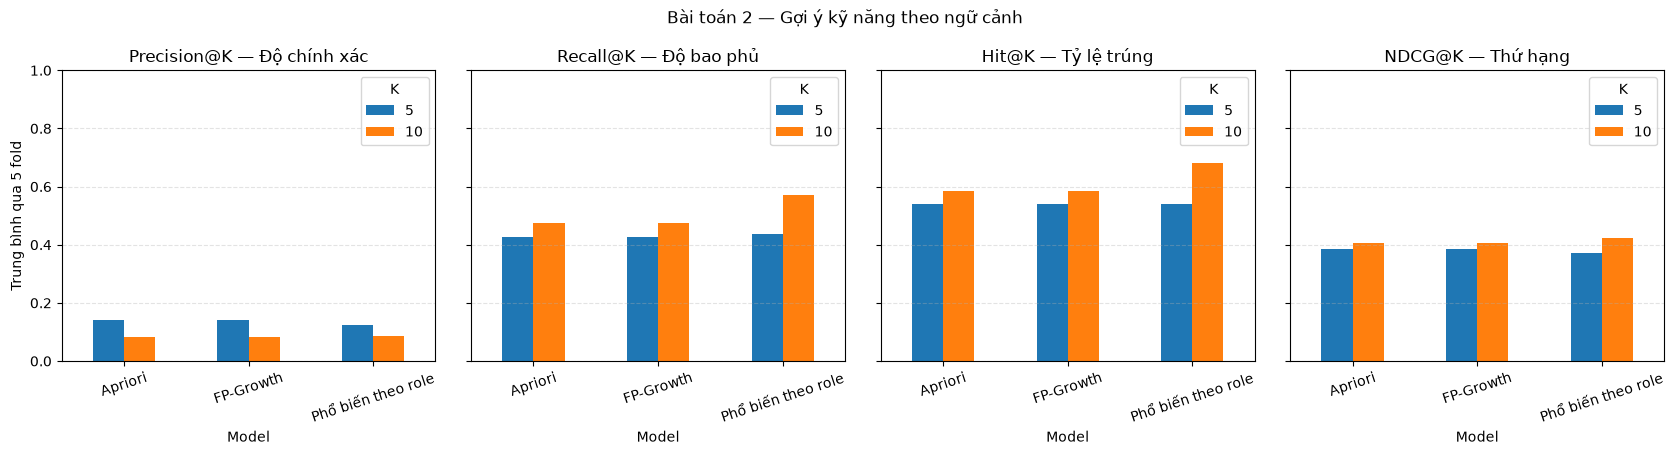

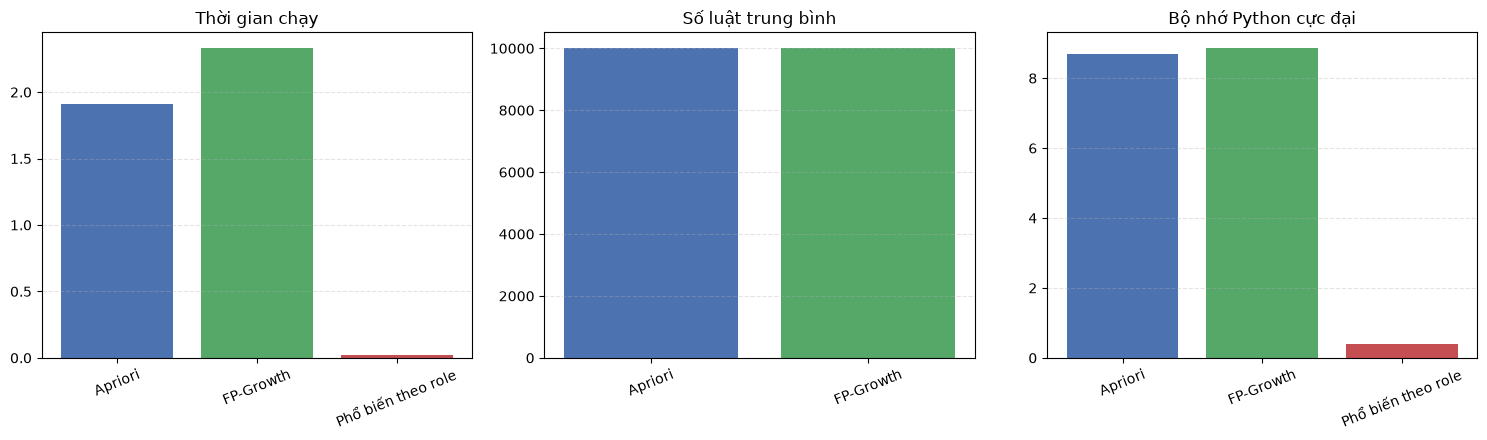

Đã lưu kết quả tại: D:\DataMining\skill-recommendation-using-association-rules\result\problem_2


In [5]:
short = {"Apriori": "Apriori", "FP-Growth": "FP-Growth", "Phổ biến theo role": "Phổ biến theo role"}
plot_df = quality_df.copy(); plot_df["Model"] = plot_df.Model.map(short)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharey=True)
for ax, metric, vn_title in zip(axes, ["Precision@K", "Recall@K", "Hit@K", "NDCG@K"],
    ["Precision@K — Độ chính xác", "Recall@K — Độ bao phủ", "Hit@K — Tỷ lệ trúng", "NDCG@K — Thứ hạng"]):
    plot_df.pivot(index="Model", columns="K", values=f"{metric}_mean").plot(kind="bar", ax=ax, ylim=(0,1), rot=18)
    ax.set_title(vn_title); ax.set_ylabel("Trung bình qua 5 fold"); ax.grid(axis="y", linestyle="--", alpha=.35); ax.legend(title="K")
fig.suptitle("Bài toán 2 — Gợi ý kỹ năng theo ngữ cảnh"); fig.tight_layout()
fig.savefig(FIGURES_DIR / "recommendation_quality.png", dpi=180, bbox_inches="tight"); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, title in zip(axes, ["Runtime median (s)", "Number of Rules mean", "Memory Usage median (MB)"],
                          ["Thời gian chạy", "Số luật trung bình", "Bộ nhớ Python cực đại"]):
    ax.bar(benchmark_df.Model, benchmark_df[col], color=["#4C72B0", "#55A868", "#C44E52"])
    ax.set_title(title); ax.tick_params(axis="x", rotation=22); ax.grid(axis="y", linestyle="--", alpha=.35)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "benchmark.png", dpi=180, bbox_inches="tight"); plt.show()
export_rules(rules_apriori, RESULT_DIR / "rules_apriori.csv")
export_rules(rules_fpgrowth, RESULT_DIR / "rules_fpgrowth.csv")
quality_df.to_csv(RESULT_DIR / "quality_metrics.csv", index=False, encoding="utf-8-sig")
fold_quality_df.to_csv(RESULT_DIR / "quality_metrics_by_fold.csv", index=False, encoding="utf-8-sig")
benchmark_df.to_csv(RESULT_DIR / "benchmark.csv", index=False, encoding="utf-8-sig")
role_coverage_df.to_csv(RESULT_DIR / "role_coverage.csv", index=False, encoding="utf-8-sig")
role_quality_df.to_csv(RESULT_DIR / "quality_by_role.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(examples).to_csv(RESULT_DIR / "recommendation_examples.csv", index=False, encoding="utf-8-sig")
print("Đã lưu kết quả tại:", RESULT_DIR.resolve())

## 6. Diễn giải

Luật theo ngữ cảnh có thể xếp hạng tốt hơn ở một số truy vấn nhưng cũng có thể không trả đủ gợi ý nếu không có luật nào khớp các skill đã biết. Hãy so sánh chất lượng xếp hạng và độ bao phủ với baseline tần suất theo role. Thí nghiệm này dự đoán skill bị ẩn khỏi hồ sơ tuyển dụng, không chứng minh được một lộ trình học theo thứ tự thời gian.